<a href="https://colab.research.google.com/github/nilanjanajui/pyrosync/blob/main/notebooks/phase3_grid_aggregation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q pandas numpy geopandas shapely pyproj pyarrow matplotlib

import json, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
from google.colab import drive

warnings.filterwarnings("ignore")
drive.mount("/content/drive")
print("PYROSYNC — PHASE 3")
print("Pandas:", pd.__version__, "| NumPy:", np.__version__, "| GeoPandas:", gpd.__version__)

Mounted at /content/drive
PYROSYNC — PHASE 3
Pandas: 2.2.3 | NumPy: 2.4.6 | GeoPandas: 1.2.0


In [2]:
BASE_DIR     = Path("/content/drive/MyDrive/Nasa App Challenges")
PROJECT_DIR  = BASE_DIR / "PyroSync"
PHASE2_DIR   = PROJECT_DIR / "data" / "cleaned" / "phase2"
PHASE3_DIR   = PROJECT_DIR / "data" / "aggregated" / "phase3"
BOUNDARY_DIR = PROJECT_DIR / "data" / "boundaries"
REPORT_DIR   = PROJECT_DIR / "reports" / "phase3"
for d in [PHASE3_DIR, BOUNDARY_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

MODIS_PATH = PHASE2_DIR / "modis_vegetation.parquet"
VIIRS_PATH = PHASE2_DIR / "viirs_vegetation.parquet"
STATE_SHP_DIR = BOUNDARY_DIR / "tiger_2024_states"   # created by Phase 2

START_DATE = pd.Timestamp("2000-11-01")
END_DATE   = pd.Timestamp("2021-12-31")
# S-NPP VIIRS starts 2012-01-20, so Jan 2012 is partial; first complete common month is Feb 2012.
COMPARISON_START = pd.Timestamp("2012-02-01")
COMPARISON_END   = pd.Timestamp("2021-12-31")

GRID_SIZE = 10_000
PROJECTED_CRS = "EPSG:6933"      # equal-area, so every cell is exactly 100 km²
GEOGRAPHIC_CRS = "EPSG:4326"

print("Comparison period:", COMPARISON_START.date(), "to", COMPARISON_END.date())
print("Grid:", GRID_SIZE, "m |", PROJECTED_CRS)

Comparison period: 2012-02-01 to 2021-12-31
Grid: 10000 m | EPSG:6933


In [3]:
def load_sensor(path, sensor):
    if not path.exists():
        raise FileNotFoundError(f"Run Phase 2 first: {path}")
    d = pd.read_parquet(path)
    for col in ["latitude", "longitude", "frp"]:
        d[col] = pd.to_numeric(d[col], errors="coerce")
    d["date"] = pd.to_datetime(d["date"], errors="coerce")
    d["satellite"] = d["satellite"].astype("string").str.strip()
    assert d[["latitude", "longitude", "date"]].notna().all().all(), f"{sensor}: missing keys"
    assert d["date"].between(START_DATE, END_DATE).all(), f"{sensor}: dates out of range"
    assert (d["frp"].isna() | (d["frp"] >= 0)).all(), f"{sensor}: negative FRP"
    d["month"] = d["date"].dt.to_period("M").dt.to_timestamp()
    print(f"{sensor}: rows={len(d):,} | {d['date'].min().date()} to {d['date'].max().date()}")
    print(d["satellite"].value_counts().to_string())
    return d

modis = load_sensor(MODIS_PATH, "MODIS")
viirs = load_sensor(VIIRS_PATH, "VIIRS")

MODIS: rows=279,986 | 2000-11-01 to 2021-12-29
satellite
Terra    143262
Aqua     136724
VIIRS: rows=797,147 | 2012-01-20 to 2021-12-31
satellite
SNPP    797147


In [4]:
shp = list(STATE_SHP_DIR.glob("*.shp"))
if not shp:
    raise FileNotFoundError("Boundary missing. Run Phase 2 first (it downloads it).")

states = gpd.read_file(shp[0])
california = states.loc[states["STATEFP"] == "06"].to_crs(GEOGRAPHIC_CRS).dissolve()
california["geometry"] = california.geometry.make_valid()
assert not california.empty

california.to_file(BOUNDARY_DIR / "california_boundary_2024.geojson", driver="GeoJSON")
california_projected = california.to_crs(PROJECTED_CRS)

print("Geometry:", california.geometry.iloc[0].geom_type, "| valid:", california.geometry.is_valid.all())
print("Bounds:", california.total_bounds.round(6))

Geometry: MultiPolygon | valid: True
Bounds: [-124.482003   32.529508 -114.131211   42.009503]


In [5]:
def project_points(df):
    pts = gpd.GeoSeries(
        gpd.points_from_xy(df["longitude"], df["latitude"]),
        index=df.index, crs=GEOGRAPHIC_CRS,
    ).to_crs(PROJECTED_CRS)
    out = df.copy()
    out["x"], out["y"] = pts.x.values, pts.y.values
    return out

modis_p = project_points(modis)
viirs_p = project_points(viirs)
print(modis_p[["latitude", "longitude", "x", "y"]].head(3))

   latitude  longitude             x             y
0   38.4464  -120.3885 -1.161584e+07  4.552722e+06
1   39.3986  -121.2372 -1.169773e+07  4.647730e+06
2   38.8607  -120.4966 -1.162627e+07  4.594214e+06


In [6]:
min_x, min_y, max_x, max_y = california_projected.total_bounds
min_ix, max_ix = int(np.floor(min_x / GRID_SIZE)), int(np.floor(max_x / GRID_SIZE))
min_iy, max_iy = int(np.floor(min_y / GRID_SIZE)), int(np.floor(max_y / GRID_SIZE))
print("Index limits: X", min_ix, "to", max_ix, "| Y", min_iy, "to", max_iy)

ca_geom = california_projected.geometry.iloc[0]
records = []
for ix in range(min_ix, max_ix + 1):
    for iy in range(min_iy, max_iy + 1):
        cell = box(ix * GRID_SIZE, iy * GRID_SIZE, (ix + 1) * GRID_SIZE, (iy + 1) * GRID_SIZE)
        if cell.intersects(ca_geom):
            records.append({"ix": ix, "iy": iy, "cell_id": f"{ix}_{iy}", "geometry": cell})

grid = gpd.GeoDataFrame(records, geometry="geometry", crs=PROJECTED_CRS)
grid["centroid_x"] = grid.geometry.centroid.x
grid["centroid_y"] = grid.geometry.centroid.y
cen = gpd.GeoSeries(grid.geometry.centroid, crs=PROJECTED_CRS).to_crs(GEOGRAPHIC_CRS)
grid["lon"], grid["lat"] = cen.x, cen.y
grid["cell_area_km2"] = grid.geometry.area / 1e6
grid["california_overlap_km2"] = grid.geometry.intersection(ca_geom).area / 1e6
grid["california_overlap_pct"] = grid["california_overlap_km2"] / grid["cell_area_km2"] * 100

assert grid["cell_id"].is_unique
grid.to_parquet(PHASE3_DIR / "california_grid_10km.parquet", index=False)
print("Cells:", f"{len(grid):,}")
print(grid[["cell_area_km2", "california_overlap_pct"]].describe().round(3))

Index limits: X -1202 to -1102 | Y 393 to 490
Cells: 4,527
       cell_area_km2  california_overlap_pct
count         4527.0                4527.000
mean           100.0                  93.653
std              0.0                  21.446
min            100.0                   0.000
25%            100.0                 100.000
50%            100.0                 100.000
75%            100.0                 100.000
max            100.0                 100.000


In [7]:
def assign_grid_cells(df, sensor):
    d = df.copy()
    d["ix"] = np.floor(d["x"] / GRID_SIZE).astype("int64")
    d["iy"] = np.floor(d["y"] / GRID_SIZE).astype("int64")
    d["cell_id"] = d["ix"].astype(str) + "_" + d["iy"].astype(str)
    out = d.merge(grid[["ix", "iy"]], on=["ix", "iy"], how="inner", validate="many_to_one")
    assert len(out) == len(d), f"{sensor}: {len(d)-len(out)} detections fall outside the grid"
    print(f"{sensor}: assigned={len(out):,} | unique cells={out['cell_id'].nunique():,}")
    return out

modis_grid = assign_grid_cells(modis_p, "MODIS")
viirs_grid = assign_grid_cells(viirs_p, "VIIRS")

MODIS: assigned=279,986 | unique cells=3,102
VIIRS: assigned=797,147 | unique cells=3,118


In [8]:
KEYS = ["ix", "iy", "cell_id", "month"]

sat = modis_grid["satellite"].str.lower()
assert sat.isin(["terra", "aqua"]).all(), "Unexpected MODIS platform"
modis_grid["is_terra"] = sat.eq("terra").astype("int64")
modis_grid["is_aqua"]  = sat.eq("aqua").astype("int64")

modis_monthly = (modis_grid.groupby(KEYS, observed=True)
    .agg(modis_all_n=("date", "size"), modis_all_frp=("frp", "sum"),
         modis_mean_frp=("frp", "mean"), modis_valid_frp_n=("frp", "count"),
         modis_terra_n=("is_terra", "sum"), modis_aqua_n=("is_aqua", "sum"))
    .reset_index())

viirs_monthly = (viirs_grid.groupby(KEYS, observed=True)
    .agg(viirs_all_n=("date", "size"), viirs_all_frp=("frp", "sum"),
         viirs_mean_frp=("frp", "mean"), viirs_valid_frp_n=("frp", "count"))
    .reset_index())

modis_monthly.to_parquet(PHASE3_DIR / "modis_cell_month.parquet", index=False)
viirs_monthly.to_parquet(PHASE3_DIR / "viirs_cell_month.parquet", index=False)

for name, df in [("MODIS", modis_monthly), ("VIIRS", viirs_monthly)]:
    print(f"{name}: cell-months={len(df):,} | cells={df['cell_id'].nunique():,} | months={df['month'].nunique()}")
print("Terra total:", f"{modis_monthly['modis_terra_n'].sum():,}",
      "| Aqua total:", f"{modis_monthly['modis_aqua_n'].sum():,}")

MODIS: cell-months=32,017 | cells=3,102 | months=254
VIIRS: cell-months=31,614 | cells=3,118 | months=120
Terra total: 143,262 | Aqua total: 136,724


In [9]:
months = pd.date_range(COMPARISON_START, COMPARISON_END, freq="MS")
cells = grid[["ix", "iy", "cell_id", "lat", "lon", "cell_area_km2", "california_overlap_pct"]]

m = modis_monthly[modis_monthly["month"].isin(months)].drop(columns="cell_id")
v = viirs_monthly[viirs_monthly["month"].isin(months)].drop(columns="cell_id")

panel = (cells.merge(pd.DataFrame({"month": months}), how="cross")
              .merge(m, on=["ix", "iy", "month"], how="left", validate="one_to_one")
              .merge(v, on=["ix", "iy", "month"], how="left", validate="one_to_one"))

COUNT_COLS = ["modis_all_n", "modis_terra_n", "modis_aqua_n", "modis_valid_frp_n",
              "viirs_all_n", "viirs_valid_frp_n"]
panel[COUNT_COLS] = panel[COUNT_COLS].fillna(0).astype("int64")
panel[["modis_all_frp", "viirs_all_frp"]] = panel[["modis_all_frp", "viirs_all_frp"]].fillna(0)
# A zero count means "no detection record", not proof of no fire. Mean FRP stays NaN when empty.
panel["modis_record_present"] = panel["modis_all_n"] > 0
panel["viirs_record_present"] = panel["viirs_all_n"] > 0

PAIRED_COLS = ["ix", "iy", "cell_id", "month", "modis_all_n", "modis_all_frp", "modis_mean_frp",
               "modis_valid_frp_n", "modis_terra_n", "modis_aqua_n", "viirs_all_n", "viirs_all_frp",
               "viirs_mean_frp", "viirs_valid_frp_n", "modis_record_present", "viirs_record_present",
               "lat", "lon", "cell_area_km2", "california_overlap_pct"]
panel = panel[PAIRED_COLS].sort_values(["month", "iy", "ix"]).reset_index(drop=True)
paired = panel[panel["modis_record_present"] | panel["viirs_record_present"]].reset_index(drop=True)

panel.to_parquet(PHASE3_DIR / "panel_cell_month_2012_2021.parquet", index=False)
paired.to_parquet(PHASE3_DIR / "paired_cell_month_2012_2021.parquet", index=False)

both = paired["modis_record_present"] & paired["viirs_record_present"]
print("Panel rows:", f"{len(panel):,}", "| months:", panel["month"].nunique())
print("Paired rows:", f"{len(paired):,}")
print("MODIS-present:", f"{paired['modis_record_present'].sum():,}",
      "| VIIRS-present:", f"{paired['viirs_record_present'].sum():,}",
      "| both:", f"{both.sum():,}")

Panel rows: 538,713 | months: 119
Paired rows: 34,841
MODIS-present: 15,482 | VIIRS-present: 31,545 | both: 12,186


In [10]:
for name, df in [("PANEL", panel), ("PAIRED", paired)]:
    assert not df.duplicated(subset=["ix", "iy", "month"]).any(), f"{name}: duplicate keys"
    assert df["month"].between(COMPARISON_START, COMPARISON_END).all()
    assert df[["lat", "lon"]].notna().all().all()

assert (panel["modis_terra_n"] + panel["modis_aqua_n"] == panel["modis_all_n"]).all()
assert (panel[COUNT_COLS] >= 0).all().all()

expected_m = int(m["modis_all_n"].sum()); expected_v = int(v["viirs_all_n"].sum())
for name, df in [("PANEL", panel), ("PAIRED", paired)]:
    assert df["modis_all_n"].sum() == expected_m, f"{name}: MODIS total mismatch"
    assert df["viirs_all_n"].sum() == expected_v, f"{name}: VIIRS total mismatch"

print("MODIS detections in window:", f"{expected_m:,}")
print("VIIRS detections in window:", f"{expected_v:,}")
print("ALL CRITICAL AGGREGATION CHECKS PASSED")

MODIS detections in window: 187,317
VIIRS detections in window: 796,962
ALL CRITICAL AGGREGATION CHECKS PASSED


(254, 8)


,month,modis_detections,modis_frp,modis_cells,viirs_detections,viirs_frp,viirs_cells,viirs_complete_month
0,2000-11-01,336,8592.4,192,NaN,NaN,NaN,False
1,2000-12-01,82,1897.7,55,NaN,NaN,NaN,False
2,2001-01-01,125,10945.0,54,NaN,NaN,NaN,False


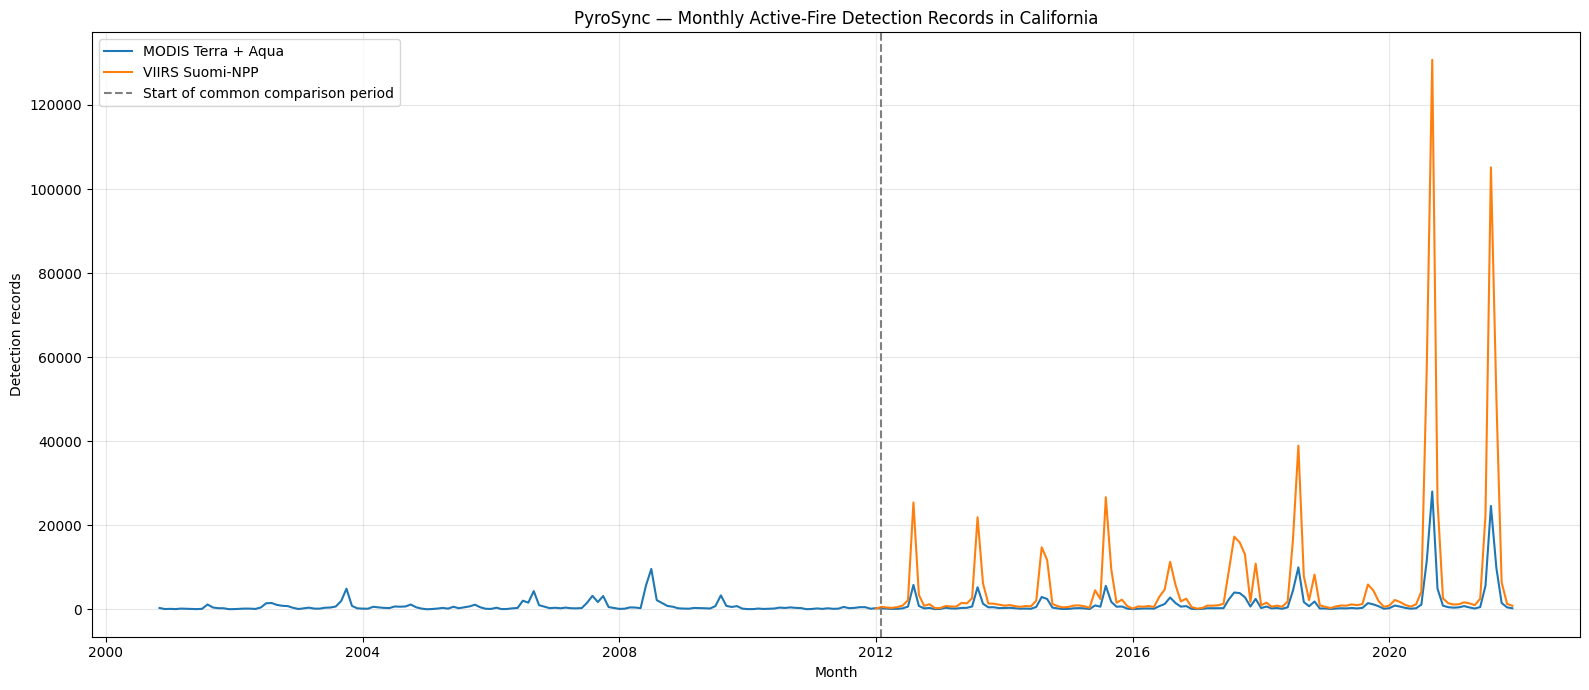

In [11]:
modis_summary = (modis_monthly.groupby("month")
    .agg(modis_detections=("modis_all_n", "sum"), modis_frp=("modis_all_frp", "sum"),
         modis_cells=("cell_id", "nunique")).reset_index())
viirs_summary = (viirs_monthly.groupby("month")
    .agg(viirs_detections=("viirs_all_n", "sum"), viirs_frp=("viirs_all_frp", "sum"),
         viirs_cells=("cell_id", "nunique")).reset_index())

monthly_summary = (modis_summary.merge(viirs_summary, on="month", how="outer")
                   .sort_values("month").reset_index(drop=True))
monthly_summary["viirs_complete_month"] = monthly_summary["month"] >= COMPARISON_START
monthly_summary.to_csv(PHASE3_DIR / "phase3_monthly_summary.csv", index=False)
print(monthly_summary.shape)
display(monthly_summary.head(3))

plt.figure(figsize=(16, 7))
plt.plot(modis_summary["month"], modis_summary["modis_detections"], label="MODIS Terra + Aqua", linewidth=1.5)
plt.plot(viirs_summary["month"], viirs_summary["viirs_detections"], label="VIIRS Suomi-NPP", linewidth=1.5)
plt.axvline(COMPARISON_START, linestyle="--", color="gray", label="Start of common comparison period")
plt.title("PyroSync — Monthly Active-Fire Detection Records in California")
plt.xlabel("Month"); plt.ylabel("Detection records")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_DIR / "phase3_monthly_detection_trends.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
metadata = {
    "project": "PyroSync", "phase": 3, "phase_name": "Spatial Grid and Monthly Aggregation",
    "study_area": "California, USA",
    "boundary": {"source": "US Census Bureau TIGER/Line 2024", "state_fips": "06",
                 "file": "california_boundary_2024.geojson"},
    "analysis_period": {"MODIS_start": str(modis["date"].min().date()), "MODIS_end": str(modis["date"].max().date()),
                        "VIIRS_start": str(viirs["date"].min().date()), "VIIRS_end": str(viirs["date"].max().date())},
    "comparison_period": {"start": str(COMPARISON_START.date()), "end": str(COMPARISON_END.date()),
                          "note": "Starts at first complete VIIRS month; Jan 2012 is partial (VIIRS begins 2012-01-20)."},
    "spatial_configuration": {"grid_size_meters": GRID_SIZE, "projection": PROJECTED_CRS,
                              "cell_assignment": "floor(projected x or y / grid size)"},
    "aggregation": {"unit": "10 km cell x calendar month", "primary_variable": "detection record count",
                    "secondary_variable": "FRP"},
    "outputs": {"panel": "all cells x all comparison months, zeros filled",
                "paired": "panel rows where either sensor has a record"},
    "missing_data_policy": "A zero count means no detection record, not proof of zero fire or valid coverage.",
    "counts": {"grid_cells": int(len(grid)), "modis_cell_months": int(len(modis_monthly)),
               "viirs_cell_months": int(len(viirs_monthly)), "panel_rows": int(len(panel)),
               "paired_rows": int(len(paired))},
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
}
with open(PHASE3_DIR / "phase3_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)
print("Metadata saved.")

Metadata saved.


In [13]:
print("=" * 80); print("PYROSYNC — PHASE 3 FINAL REPORT"); print("=" * 80)
print(f"\nBoundary: Census TIGER 2024 | Grid: {GRID_SIZE//1000} km, {PROJECTED_CRS}, {len(grid):,} cells")
print(f"MODIS: {modis['date'].min().date()} to {modis['date'].max().date()} | rows {len(modis_grid):,}")
print(f"VIIRS: {viirs['date'].min().date()} to {viirs['date'].max().date()} | rows {len(viirs_grid):,}")
print(f"Comparison period: {COMPARISON_START.date()} to {COMPARISON_END.date()}")
print(f"\nCell-months: MODIS {len(modis_monthly):,} | VIIRS {len(viirs_monthly):,} | "
      f"panel {len(panel):,} | paired {len(paired):,}")
print(f"Both-present cell-months: {both.sum():,}")
print("\nSaved files:")
for d in [PHASE3_DIR, BOUNDARY_DIR, REPORT_DIR]:
    for p in sorted(d.iterdir()):
        if p.is_file():
            print(f"  {p.name:45} {p.stat().st_size/(1024**2):8.2f} MB")
print("\nPHASE 3 COMPLETED")

PYROSYNC — PHASE 3 FINAL REPORT

Boundary: Census TIGER 2024 | Grid: 10 km, EPSG:6933, 4,527 cells
MODIS: 2000-11-01 to 2021-12-29 | rows 279,986
VIIRS: 2012-01-20 to 2021-12-31 | rows 797,147
Comparison period: 2012-02-01 to 2021-12-31

Cell-months: MODIS 32,017 | VIIRS 31,614 | panel 538,713 | paired 34,841
Both-present cell-months: 12,186

Saved files:
  california_grid_10km.parquet                      0.16 MB
  modis_cell_month.parquet                          0.36 MB
  paired_cell_month_2012_2021.parquet               0.70 MB
  panel_cell_month_2012_2021.parquet                2.09 MB
  phase3_metadata.json                              0.00 MB
  phase3_monthly_summary.csv                        0.01 MB
  viirs_cell_month.parquet                          0.36 MB
  california_boundary_2024.geojson                  0.32 MB
  tl_2024_us_state.zip                              9.49 MB
  phase3_monthly_detection_trends.png               0.29 MB

PHASE 3 COMPLETED
